# Reuse

**Reuse: 한 번 만들고 재사용.** teacher를 매 step 돌리는 대신, teacher가 만든 결과물(soft label, logits, 임베딩, 가중치)을 한 번 만들어 두고 여러 번 쓰는 방법.

---
## 1. FKD([arXiv: 2112.01528](https://arxiv.org/abs/2112.01528))

요약: teacher가 crop마다 낸 soft label을 crop 좌표와 같이 파일로 미리 저장해 두고, 학습 때는 teacher 없이 그 파일만 읽어서 KD를 하는 방법.

일반 KD는 매 iteration 학습 이미지를 큰 teacher에 통과시켜야 해서 계산 대부분이 student가 아니라 teacher에 쓰임.
teacher 가중치는 학습 내내 고정이니까 그 forward를 epoch 사이에 공유할 수 없나?의 연구

학습할 때 저장된 좌표로 같은 crop을 다시 잘라 student에 넣고, 저장된 soft label과 cross-entropy를 걸어 한 이미지에서 crop 여러 개(m개)를 같은 mini-batch에 넣고 이미지 로딩도 줄임. 
저장 용량 때문에 1000-class 확률 전체 대신 Top-K(K=5)만 저장하는 압축 방식도 4가지 비교.

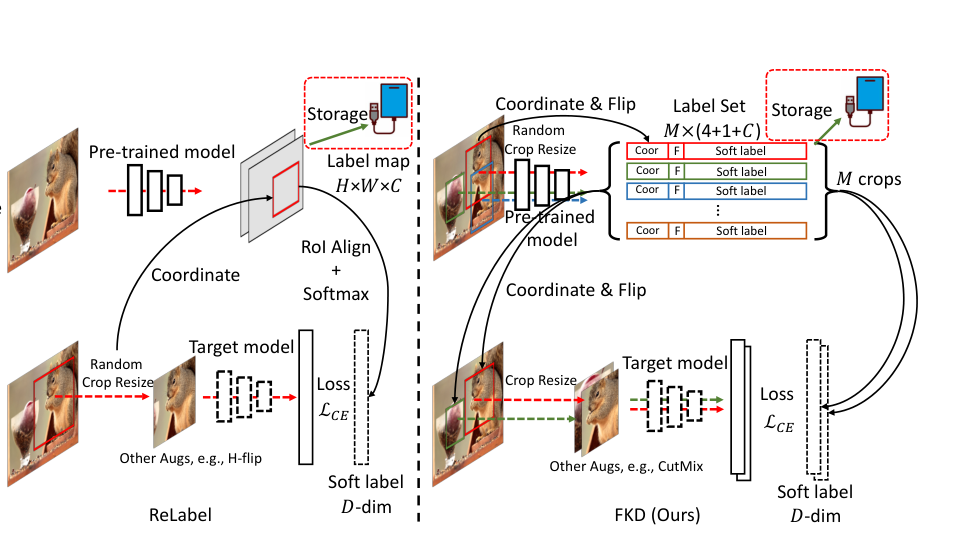

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/01_FKD/figs/p02_1.png")

- 효율화 방식: 이미지마다 random crop 좌표 M개, flip 여부, 각 crop의 teacher soft label(Top-K)을 미리 파일로 저장해 두고 학습 때는 저장된 좌표로 crop을 재현해 label을 그대로 써서 teacher forward를 아예 없앰. 한 이미지의 crop 여러 개를 같은 mini-batch에 넣어 이미지 로딩 횟수도 줄임.
- 얻는 것:
  - 비슷한 성능의 oracle KD(FunMatch) 대비 3~5배 빠름.
  - 같은 하이퍼파라미터, teacher로 MEAL V2를 2~4배 가속.
  - ViT-T에서 DeiT distillation 프로토콜 대비 0.15배 자원.
  - ReLabel 대비 ResNet-50 78.9→79.8%(+0.9%p), ResNet-101 80.7→81.7%(+1.0%p). 학습 시간은 ReLabel(+0.5%)보다 아주 약간 짧음.
- 잃는 것:
  - FunMatch(80.5%)보다 0.7%p 낮음(79.8%).
  - batch에 넣는 같은 이미지 crop 수 m이 커지면 급락.
- 옮겨 간 비용:
  - label 생성 단계로 옮겨 감. Generating label: 느림 이라고만 쓰고 GPU-시간은 안알려줌.
- 어떻게 쟀나: 단위 = 상대 배수(×), 상대 학습 시간(%), 디스크 용량(GB/TB)
- 설정: EfficientNet-L2-ns-475 teacher → ResNet-50/101, MobileNet, ViT-T/DeiT, SReT. MEAL V2 비교는 SENet154+ResNet152 앙상블 teacher. 자기지도 실험은 S2-BNN(ReActNet), ResNet-50. ImageNet-1K.
- 평균 정확도 외 평가: ImageNet ReaL·ImageNetV2 3지표. COCO 검출·인스턴스 분할 전이. Grad-CAM 시각화. label 종류 간 cross-entropy 거리 분석.
- 위치: [원문](https://arxiv.org/abs/2112.01528) · [코드](https://github.com/szq0214/FKD)
- 메모:
  - "3~5배"는 생성 비용을 뺀 학습 단계만의 주장.
  - ReLabel 대비 비교도 생성 비용이 크게 다른 두 방법을 학습 시간만으로 비교한 것.

---
## 2. ReLabel ([arXiv: 2101.05022](https://arxiv.org/abs/2101.05022))

요약: 강한 분류기로 ImageNet 이미지마다 위치별 label 지도(15×15×1000)를 딱 한 번 만들어 저장하고, random crop 위치에 맞춰 잘라서 label로 쓰는 방법.

ImageNet은 이미지당 label이 하나뿐인데, 실제 사진엔 물체가 여러 개 있는 경우가 많다. 그래서 random crop을 하면 crop 안에 정답 물체가 없는데도 원래 label로 학습하는 일이 생긴다.

따라서 JFT-300M으로 학습한 EfficientNet-L2를 machine annotator로 쓴다. 마지막 pooling 직전 출력을 그대로 꺼내면 이미지 위치마다 class 점수가 나오는 지도가 된다. 이걸 이미지 전체(475×475)에 대해 한 번만 뽑아 저장한다.

LabelPooling. crop 위치의 label map 영역을 pooling해 crop별 label을 만듦

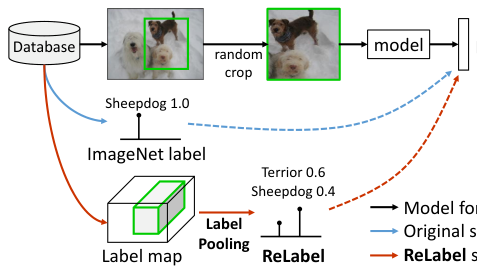

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/02_ReLabel/figs/p04_2.png")

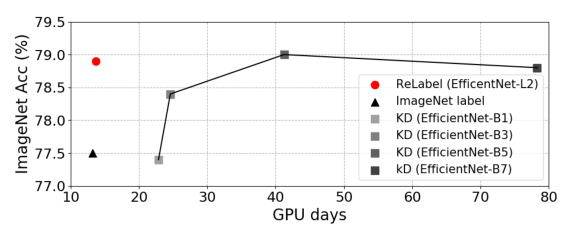

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/02_ReLabel/figs/p07_1.png")

- 효율화 방식: 강한 분류기(EfficientNet-L2, JFT-300M 사전학습)의 마지막 pooling 전 출력을 이용해 이미지당 15×15×1000 label map을 crop 없이 475×475 전체 이미지로 딱 한 번 만들어 저장함. 학습 때는 random crop 좌표에 해당하는 영역을 RoIAlign → GAP → softmax(LabelPooling)로 잘라 label로 씀. 매 iteration teacher forward가 없음.
- 얻는 것:
  - ResNet-50 77.5→78.9%(+1.4%p). 
  - EfficientNet-B5/B7 teacher로 KD한 것과 비슷한 정확도(본문: B7 KD 79.0%, ReLabel 78.8%)를 KD 41·78 GPU-일 대신 13.6 GPU-일로 얻음.
  - 표준 학습 대비 추가 학습 시간 +0.5%.
- 잃는 것:
  - annotator가 약하면 오히려 손해. EfficientNet-B1을 annotator로 쓰면 76.1%로 원래 label(77.5%)보다 낮아짐.
  - 저장 class 수 k에 따라 달라짐. k=1 78.2%, k=5 78.9%, k=10 78.7%.
- 옮겨 간 비용:
  - 사전 계산: label map 생성 약 10 GPU-시간. ResNet-50 전체 학습(328 GPU-시간)의 3.3%(§3.3).
  - 저장: 모든 class를 다 저장하면 1TB 이상, Top-5만 저장하면 10GB(§3.3).
- 어떻게 쟀나: 단위 = GPU-시간·GPU-일, 상대 학습 시간(%), 저장(GB/TB), bit 수
- 설정: EfficientNet-L2(475×475) annotator → ResNet-18/50/101, EfficientNet-B0~B3, ReXNet. ImageNet-1K, 300 epoch.
- 평균 정확도 외 평가: multi-label 평가(ReaL, Shankar et al.), ImageNetV2. 강건성 FGSM·ImageNet-A·C·Background Challenge. 전이: fine-grained 분류, COCO 검출·분할, COCO multi-label. crop–정답 박스 IoU별 label 신뢰도.
- 위치: [원문](https://arxiv.org/abs/2101.05022) · [공식 코드](https://github.com/naver-ai/relabel_imagenet)
- 메모:
  - KD 비교에서 본문 숫자(B7 KD 79.0%, ReLabel 78.8%)와 그림에서 읽히는 값이 조금 다름. 인용할 땐 본문 숫자를 씀.

---
## 4. TinyViT ([arXiv: 2207.10666](https://arxiv.org/abs/2207.10666))

요약: ImageNet-21k로 작은 ViT를 사전학습할 때, teacher의 sparse logits와 증강 seed를 epoch마다 디스크에 저장해 두고 teacher 없이 distill하는 방법

작은 ViT는 큰 데이터로 사전학습해도 잘 안 오르는데, distillation을 같이 하면 오른다. 

저장 단계에서 teacher가 증강된 이미지를 보고 낸 Top-K logits를 저장한다. 이때 증강 파라미터를 직접 저장하는 대신 random seed(4바이트)만 저장한다. 학습 단계에서는 같은 seed로 같은 증강을 재현하고 저장된 logits로 distill한다. 

**중요** : 부록 B의 전체 비용 계산. 저장 비용까지 넣고도 온라인 KD보다 싸다고 숫자로 보여 준 논문.

teacher logits와 증강 seed를 저장하고 저장된 것으로 teacher 없이 student 학습.

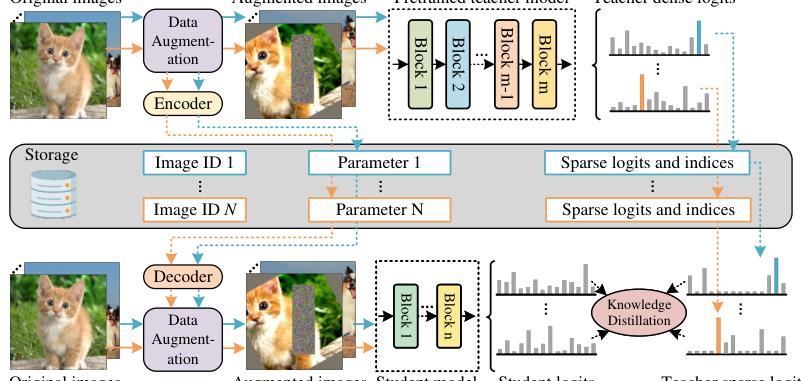

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/04_TinyViT/figs/p05_1.png")

- 효율화 방식: IN-21k pretraining distillation에서 epoch마다 teacher의 sparse logits(Top-K)와 증강 random seed(4바이트)를 디스크에 저장. 학습 때는 seed로 같은 증강(crop·RandAugment 등)을 재현하고 저장된 logits로 distill.
- 얻는 것:
  - Florence teacher 기준 총 232.4 GPU-일(logits 저장 92.4 + TinyViT-21M 90 epoch 학습 140.0)로, 온라인 distillation 330.9 GPU-일보다 29.8% 적음
  - TinyViT-21M ImageNet-1k 84.8%(21M 파라미터로 IN-21k 사전학습 Swin-B 85.2%와 비슷, 4.2배 작음).
- 잃는 것:
  - 저장 logits 수 K가 작으면 정확도가 떨어지고, K를 늘리면 포화할 때까지 오르는 대신 저장은 선형으로 늘어남.
  - seed로 증강을 재현하는 방식이라 저장할 때와 학습할 때 데이터 로더·증강 구현·라이브러리 버전이 같아야 함.
- 옮겨 간 비용:
  - 사전 계산: Florence top-100 logits 저장 92.4 GPU-일.
  - 저장: IN-21k K=100·90 epoch 481GB, IN-1k K=10·300 epoch 16GB.
- 어떻게 쟀나: 단위 = GPU-일·GPU-시간, 배수, GPU 메모리(GB), 저장(GB), MACs, throughput, Images Seen(M)
- 설정: Swin-L, BEiT-L, CLIP-ViT-L/14, Florence teacher → TinyViT-5M/11M/21M, DeiT, Swin-T. ImageNet-21k 90 epoch pretraining → ImageNet-1k 30 epoch fine-tune.
- 평균 정확도 외 평가: ImageNet-Real·V2. 선형 probe 5개, few-shot 4개 데이터셋. COCO 검출 전이. class 간 Pearson 상관 heatmap. hard sample 분석. 데이터 규모 곡선.
- 위치: [원문](https://arxiv.org/abs/2207.10666)  [공식 코드](https://github.com/microsoft/Cream/tree/main/TinyViT)
- 메모:
  - 여러 student에 재사용했다는걸 동기로 드는데 실제로 몇 개 student에 썼는지와 그걸로 나눈 비용은 안 나옴.
  - 최고 결과와 비용 계산에 쓴 Florence teacher는 공개 안 됨.

---
## 5. Dataset Reinforcement ([arXiv: 2303.08983](https://arxiv.org/abs/2303.08983))

요약: 강한 teacher 앙상블의 출력을 증강 파라미터와 함께 데이터셋 자체에 넣어 한 번 배포하고, 사용자는 data loader만 바꿔 teacher 없이 학습하게 하는 방법.

데이터 증강은 학습 비용이 거의 없지만 이득이 작고 KD는 이득이 크지만 매번 teacher를 돌려야 힘.

80개가 넘는 모델·앙상블로 KD를 해 보고 가장 좋은 teacher(IG-ResNeXt 4개 앙상블)를 고름. 이미지마다 증강 400개(RRC + RandAugment/RandomErase)를 만들어 증강 파라미터와 teacher의 Top-10 확률을 저장.

데이터 증강(왼쪽), KD(가운데), Dataset Reinforcement(오른쪽: 한 번 강화해서 여러 번 학습)

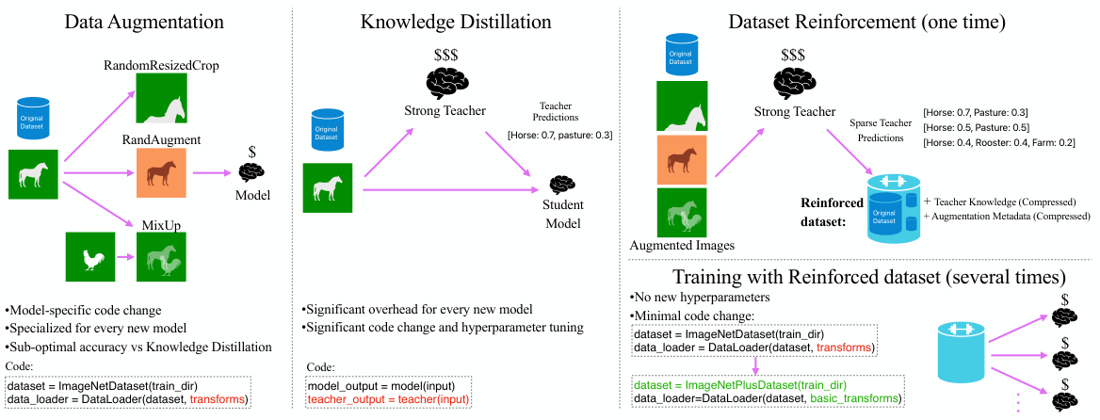

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/05_DR/figs/p02_1.png")

- 효율화 방식: 강한 teacher의 출력을 이미지당 증강 400개 파라미터와 Top-10 확률로 한 번 저장한 데이터셋을 만듦. 사용자는 data loader만 바꿔서 teacher 없이 학습하고 같은 데이터셋을 여러 구조·여러 번 학습에 재사용가능.
- 얻는 것:
  - 표준 ImageNet 학습 대비 학습 시간 1.12배(MobileNetV3-Large), 1.01배(ResNet-50), 0.99배(Swin-T).
  - 표준 ImageNet 학습 대비 ResNet-50 +1.7%(IN val), +3.5%(V2), +10.0%(IN-R), ECE 9.9% 감소.
  - FunMatch, DeiT와 비슷하거나 나은 정확도를 teacher 없이 얻음.
- 잃는 것:
  - 이미지당 증강 400개가 상한. 1000 epoch 학습이면 증강 하나를 평균 2.5번 반복.
  - teacher의 편향이 데이터셋에 고정돼서 모든 사용자에게 그대로 전달.
- 옮겨 간 비용:
  - 생성: ImageNet+ 2205 GPU-시간(64×A100). ResNet-50 300 epoch 학습(206 GPU-시간)의 약 10.7배. ImageNet+-Small 551 GPU-시간.
  - 저장: 61GB(raw, 표 2) / 37.5GB
- 어떻게 쟀나: 단위 = GPU-시간, 상대 학습 시간(×), wall-clock, 저장(GB)
- 설정: IG-ResNeXt 앙상블 teacher → 25개 구조(CNN·ViT·Swin·MobileNet 등). ImageNet-1K, 150/300/1000 epoch, KL 손실만, 하이퍼파라미터는 ImageNet 기본값 그대로. CIFAR-100·Flowers·Food에도 적용.
- 평균 정확도 외 평가: 분포 이동 강건성 ImageNet-V2·A·R·Sketch·ObjectNet·C. calibration ECE. 전이 COCO 검출·분할, ADE20K, CIFAR-100·Flowers·Food 미세조정. 생성·저장 비용 비교표.
- 위치: [원문](https://arxiv.org/abs/2303.08983)  [공식 코드](https://github.com/apple/ml-dr)
- 메모:
  - 얻는 것의 분모가 온라인 KD가 아니라 teacher 없는 표준 학습. 이 기준으론 생성 비용(약 10.7회 학습분)이 회수 불가. 효율화보다는 일회성 비용으로 정확도·강건성을 사서 배포하는 방식으로 읽는 게 맞는 것 같다.

---
## 6. MobileCLIP ([arXiv: 2311.17049](https://arxiv.org/abs/2311.17049))

요약: DR을 이미지–텍스트(CLIP)로 확장. 합성 캡션·증강·teacher 임베딩을 데이터셋에 한 번 저장(DataCompDR)해서 모바일용 작은 CLIP을 빠르게 학습.

- 효율화 방식: DataComp 각 샘플에 CoCa 합성 캡션 5개, 이미지 증강 파라미터(12M은 30개, 1B는 10개), CLIP teacher 앙상블의 이미지·텍스트 임베딩을 한 번 저장함(DataCompDR). 학습 때는 저장된 임베딩으로 affinity distillation을 해서 teacher와 캡셔너 forward를 없앰.
- 얻는 것:
  - 강화 안 한 DataComp 대비 학습 효율(iteration) 10배, 데이터 효율 100배.
  - DataComp-1B의 12M 부분집합만으로 120 epoch 후 ImageNet zero-shot 71.7%
- 잃는 것:
  - 학습 중 바뀌는 증강(RangeAugment)은 저장된 teacher 출력 쪽엔 적용 못 함.
  - 샘플당 저장 증강이 10~30개로 고정이라 여러 epoch 돌리면 같은 view가 반복됨.
  - 합성 캡션의 오류, 편향이 데이터셋에 박혀서 계속 재사용.
- 옮겨 간 비용:
  - 저장: DataCompDR-12M 1.9TB(원본 0.9TB), DataCompDR-1B 140TB(원본 90TB)(Pickle+Gzip·BFloat16).
- 어떻게 쟀나: 단위 = 1 epoch wall-clock 시간, seen samples, iteration, 배수, 저장(TB), iPhone 12 Pro Max latency(ms) 
- 설정: CLIP ViT-L/14 앙상블 teacher·CoCa 캡셔너 → MobileCLIP-S0/S1/S2/B. DataComp-12M·DataComp-1B. ablation은 batch 8,192·45k iteration(약 30 epoch).
- 평균 정확도 외 평가: DataComp 38개 데이터셋 평균, ImageNet 분포 이동, retrieval R@1(COCO·Flickr30k), ARO(관계·속성·순서 이해) 벤치마크, 모바일 기기 latency.
- 위치: [원문](https://arxiv.org/abs/2311.17049)  [공식 코드](https://github.com/apple/ml-mobileclip)
- 메모:
  - 16배를 teacher 재사용 효과로 인용하면 과장이다. teacher 출력 재사용만의 몫은 약 3.2배.

---
## 7. Are Large-scale Soft Labels Necessary? (LPLD) ([arXiv: 2410.15919](https://arxiv.org/abs/2410.15919))

요약: dataset distillation(SRe2L 계열)에서 이미지보다 훨씬 큰 soft label 저장을 줄이는 방법. class 내 다양성을 높인 뒤 label을 무작위로 40배까지 잘라냄.

SRe2L 계열 dataset distillation은 (1) 원본으로 모델 학습(squeeze), (2) 그 모델의 BN 통계로 합성 이미지 생성(recover), (3) 합성 이미지에 증강을 걸 때마다 teacher soft label을 저장(relabel)한다. 그런데 (3)의 soft label이 이미지보다 훨씬 크다. 아래 그림을 보면 ImageNet-1K IPC200에서 이미지가 몇 GB인데 label은 113GB다.

총 저장(이미지+label) 대비 정확도. 원 크기가 저장량, 아래 표에서 label이 이미지보다 훨씬 큼

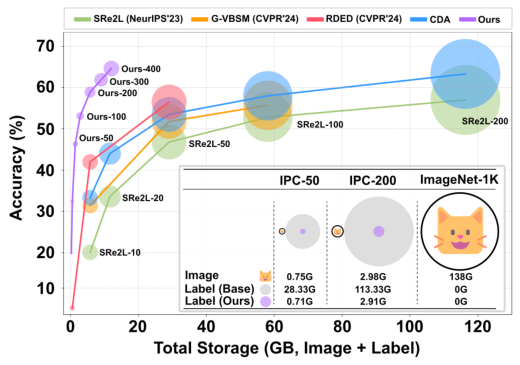

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/09_LPLD/figs/p01_1.png")

기존(SRe2L/CDA, 왼쪽)은 모든 class를 섞어 batch 통계를 맞추고 제안 방법(오른쪽)은 class별로 묶어 맞춤

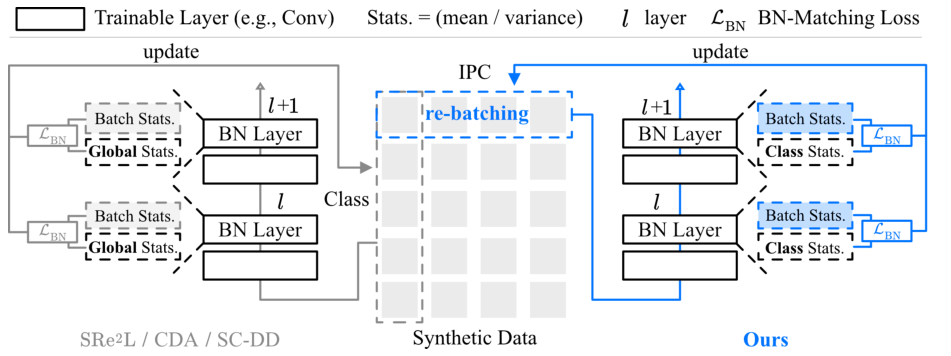

In [ ]:
from IPython.display import Image

Image("../Related Work/Efficient KD papers/3_Reuse/번역/09_LPLD/figs/p05_1.png")

- 효율화 방식: SRe2L 계열 dataset distillation(squeeze → recover → relabel)에서 epoch·증강마다 저장하는 soft label 양을 줄임. recover 단계에서 같은 class끼리 batch를 묶고 class별 BN 통계로 이미지를 합성해 class 내 다양성을 높인 뒤, 저장된 label을 random pruning하고 batch 단위로 섞은 label pool에서 무작위로 재사용.
- 얻는 것:
  - ImageNet-1K IPC200: label 저장 113GB→2.8GB(40× 압축)이면서 압축 안 한 SRe2L(57.0%) 대비 +2.6%(59.6%).
  - 같은 압축률끼리는 CDA보다 높음. IPC200 40×: CDA 54.4% vs LPLD 59.6%.
  - ImageNet-21K-P IPC20: 1285GB→32GB(40×)로 SRe2L보다 높음.
- 잃는 것:
  - IPC가 작으면 압축 손실이 큼. ImageNet-1K IPC10 1× 34.6% → 40× 20.2%.
  - label을 다 만든 뒤 고르는 방식이라 생성 비용(teacher forward)은 그대로. 학습 epoch도 그대로라 학습 시간도 안 줄어듦.
- 옮겨 간 비용:
  - squeeze 단계에서 원본 데이터 1 epoch를 더 돌아 class별 BN 통계를 계산.
- 어떻게 쟀나: 단위 = 저장 용량(GB·MB), 압축 배수(1×~100×), label/image 저장 비율, top-1
- 설정: ResNet-18(squeeze·recover·relabel) → ResNet-18/50/101, MobileNetV2, EfficientNet-B0, Swin-V2(검증). Tiny-ImageNet·ImageNet-1K·ImageNet-21K-P. CDA 하이퍼파라미터.
- 평균 정확도 외 평가: class 내 feature cosine similarity(표 1), 원본과의 MMD, cross-architecture 일반화, pruning metric 비교, BN 통계 안정화에 필요한 update 수의 이론 bound.
- 위치: [원문](https://arxiv.org/abs/2410.15919)  [공식 코드](https://github.com/he-y/soft-label-pruning-for-dataset-distillation)
- 메모:
  - 초록의 +2.6%는 가장 약한 baseline(SRe2L 1×) 대비. 같은 압축률 비교(CDA 대비 +5.2%p at 40×)가 이 방법의 진짜 강점으로 보인다.